# Example: Household consumption forecasting

For this example we use the UCI Individual Household Eletric Power Consumption dataset available [here](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption)

## Imports

In [ ]:
from datetime import datetime

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

from u2demo_time_series_forecasting.constants.paths import LEADERBOARD_FILENAME, MODEL_DIR
from u2demo_time_series_forecasting.data_models import ForecastInput, ForecastTrainingInput
from u2demo_time_series_forecasting.predict import predict
from u2demo_time_series_forecasting.train import train

## Data Loading and Preprocessing

- Loading the data from the UCI dataset
- Convert power column to energy
- Filling missing values
- Resample to hourly data

In [2]:
individual_household_electric_power_consumption = fetch_ucirepo(id=235)

df_raw = individual_household_electric_power_consumption.data.features

df_raw.head()

./.venv/lib/python3.12/site-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [3]:
# Convert "?" to NaN and ensure numeric type for "Global_active_power"
df_raw["Global_active_power"] = df_raw["Global_active_power"].replace("?", np.nan).astype(float)

# Create a "time" column by combining "Date" and "Time"
df_raw["time"] = df_raw["Date"] + " " + df_raw["Time"]
df_raw["time"] = pd.to_datetime(df_raw["time"], format="%d/%m/%Y %H:%M:%S")

# Create "value" column by converting "Global_active_power" from kW to watt-minutes (Wmin)
df_raw["value"] = df_raw["Global_active_power"].astype(float) * 1000 / 60

df = df_raw[["time", "value"]].copy()

In [4]:
def fill_energy_gaps(
    df: pd.DataFrame,
    value_col: str = "value",
    freq: str = "1min",
    short_gap: int = 15,  # minutes
    medium_gap: int = 180,  # minutes (3 hours)
    seasonal_lag: int = 1440,  # 1 day for minutely data
) -> pd.DataFrame:
    """
    Fill missing values in minutely energy time series based on gap size.

    Parameters
    ----------
    df : pd.DataFrame
        Must have a DatetimeIndex and a value column.
    value_col : str
        Column name for the time series.
    freq : str
        Expected frequency (default: '1min').
    short_gap : int
        Max size (in minutes) for linear interpolation.
    medium_gap : int
        Max size (in minutes) for time-of-day imputation.
    seasonal_lag : int
        Lag for seasonal fill (default: 1440 minutes = 1 day).

    Returns
    -------
    pd.DataFrame
        DataFrame with filled values

    """
    df = df.copy()

    # Ensure proper frequency (important!)
    df = df.asfreq(freq)

    values = df[value_col]

    # --- Identify gaps ---
    is_na = values.isna()
    gap_id = (is_na != is_na.shift()).cumsum()
    gap_sizes = is_na.groupby(gap_id).transform("sum")

    # --- 1. Short gaps → linear interpolation ---
    short_mask = is_na & (gap_sizes <= short_gap)
    df.loc[short_mask, value_col] = values.interpolate(method="time")

    # --- 2. Medium gaps → time-of-day mean ---
    medium_mask = is_na & (gap_sizes > short_gap) & (gap_sizes <= medium_gap)

    if medium_mask.any():
        # Compute time-of-day averages (excluding NaNs)
        time_means = df.groupby(df.index.time)[value_col].transform("mean")
        df.loc[medium_mask, value_col] = time_means[medium_mask]

    # --- 3. Long gaps → seasonal (previous day) ---
    long_mask = is_na & (gap_sizes > medium_gap)

    if long_mask.any():
        seasonal_values = df[value_col].shift(seasonal_lag)
        df.loc[long_mask, value_col] = seasonal_values[long_mask]

    # --- 4. Final fallback (in case seasonal also missing) ---
    df[value_col] = df[value_col].ffill().bfill()

    df[value_col] = df[value_col].round(1)

    return df

In [5]:
df = df.set_index("time").pipe(fill_energy_gaps, value_col="value").reset_index()

In [6]:
# Resample to hourly data to get Wh values
df = df.set_index("time").resample("h").sum().reset_index()

df.head()

,time,value
0,2006-12-16 17:00:00,2533.6
1,2006-12-16 18:00:00,3631.8
2,2006-12-16 19:00:00,3400.5
3,2006-12-16 20:00:00,3268.5
4,2006-12-16 21:00:00,3056.7


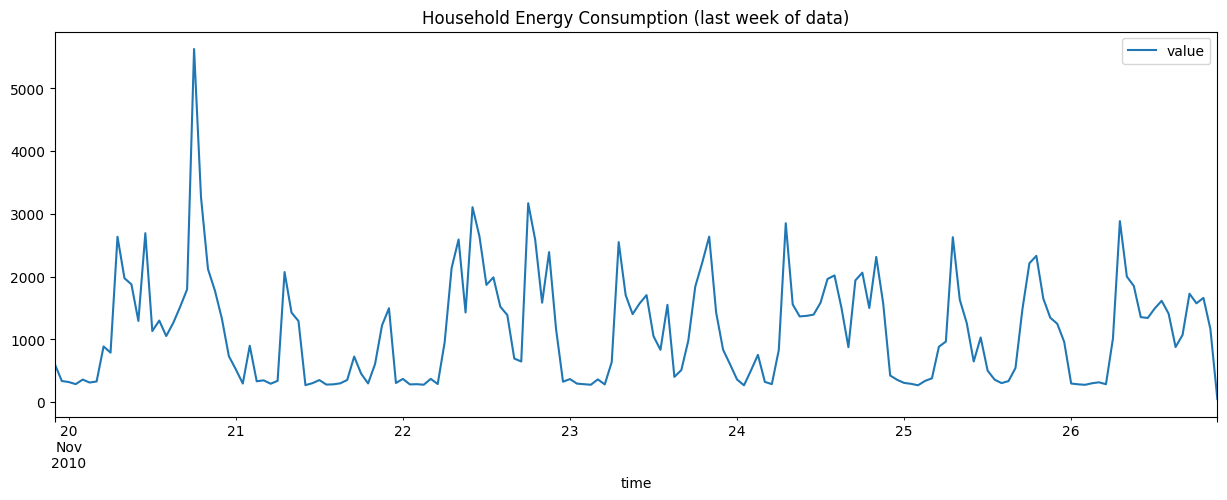

In [7]:
df.iloc[-24 * 7 :].plot(x="time", y="value", figsize=(15, 5), title="Household Energy Consumption (last week of data)")

plt.show()

## Training models on historical data

In [8]:
training_time_series = df.to_dict(orient="records")

training_dict = {
    "forecast_type": "stochastic",
    "time_parameters": {"timestep_minutes": 60, "horizon_hours": 24, "scheduling_time": datetime.now().isoformat()},
    "model_config": {
        "model_id": "uci-household-energy-consumption",
        "model_preset": "fast_training",  # use "fast_training" or "chronos2" for CPU, switch to "medium_quality" or "best_quality" for better performance with GPU
        "model_version": "1.0.0",
        "lookback_steps": 2048,
        "eval_metric": "WQL",
        "quantile_levels": [0.1, 0.5, 0.9],
    },
    "target_series": {
        "series_id": "uci-household-energy-consumption",
        "variable_name": "global_active_energy",
        "asset_id": "house-1",
        "asset_type": "household",
        "unit": "Wh",
        "unitIri": "http://qudt.org/vocab/unit/W-HR",
        "training_values": training_time_series,
    },
    # You can optionally add exogenous variables
    # "location": {
    #     "latitude": 48.778611,
    #     "longitude": 2.290556,
    # },
    # "features": ["weather", "temporal"],
}

training_input_data = ForecastTrainingInput(**training_dict)

In [9]:
train(training_input_data)

Beginning AutoGluon training...
AutoGluon will save models to './models/uci-household-energy-consumption_1.0.0'
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.3
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP PREEMPT_DYNAMIC Thu Jun  5 18:30:46 UTC 2025
CPU Count:          28
Pytorch Version:    2.7.1+cu126
CUDA Version:       12.6
GPU Memory:         GPU 0: 11.99/11.99 GB
Total GPU Memory:   Free: 11.99 GB, Allocated: 0.00 GB, Total: 11.99 GB
GPU Count:          1
Memory Avail:       11.07 GB / 15.46 GB (71.6%)
Disk Space Avail:   85.25 GB / 502.90 GB (17.0%)
Setting presets to: fast_training

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': WQL,
 'freq': 'h',
 'hyperparameters': 'very_light',
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 24,
 'quantile_levels': [0.1, 0.5, 0.9],
 'random_seed': 123,
 'refit_full': False,
 'skip_model_selection': False,

## Displaying models' performance

The score columns correspond to the chosen `eval_metric`, in this case it is Weighted Quantile Loss (WQL)  
In addition the Weighted Absolute Percentage Error (WAPE) is computed.

Note: All metrics signs have been flipped to keep a logic of "higher is better" for all metrics

In [10]:
eval_df = pd.read_csv(MODEL_DIR / "uci-household-energy-consumption_1.0.0" / LEADERBOARD_FILENAME, index_col=False)
eval_df

,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order,WAPE
0,DirectTabular,-0.183813,-0.234470,0.195442,0.187211,3.313335,4.0,-0.252334
1,WeightedEnsemble,-0.185762,-0.231371,1.355048,1.309968,0.299249,7.0,-0.257868
2,ETS,-0.250488,-2.005979,4.598195,2.545077,0.011520,5.0,-0.350561
3,SeasonalNaive,-0.282360,-0.356038,1.158778,1.121891,0.011602,2.0,-0.451520
4,Theta,-0.373672,-0.324755,1.383183,2.088378,0.011094,6.0,-0.407518
5,RecursiveTabular,-0.374011,-0.419588,0.097105,0.091333,1.189342,3.0,-0.274281
6,Naive,-0.481198,-0.442192,1.146393,1.376569,0.012526,1.0,-0.498873


## Forecasting on unseen data

In [11]:
# For forecasting, we hold out the last 24 hours of data and keep the 2048 hours before that as lookback data for the model
df_forecast = df.iloc[-2048 - 24 : -24]

In [12]:
forecasting_time_series = df_forecast.to_dict(orient="records")

forecasting_dict = {
    "forecast_type": "stochastic",
    "time_parameters": {"timestep_minutes": 60, "horizon_hours": 24, "scheduling_time": datetime.now().isoformat()},
    "model_id": "uci-household-energy-consumption",
    "model_version": "1.0.0",
    "target_series": {
        "series_id": "uci-household-energy-consumption",
        "variable_name": "global_active_energy",
        "asset_id": "house-1",
        "asset_type": "household",
        "unit": "Wh",
        "unitIri": "http://qudt.org/vocab/unit/W-HR",
        "historical_values": forecasting_time_series,
    },
    # You can optionally add exogenous variables
    # "location": {
    #     "latitude": 48.778611,
    #     "longitude": 2.290556,
    # },
    # "features": ["weather", "temporal"],
}

forecasting_input_data = ForecastInput(**forecasting_dict)

In [13]:
forecast = predict(forecasting_input_data)

2026-04-16 10:34:51,937 - u2 - INFO - Loading predictor from ./models/uci-household-energy-consumption_1.0.0
Loading predictor from path ./models/uci-household-energy-consumption_1.0.0
2026-04-16 10:34:51,956 - u2 - INFO - Predictor loaded and persisted
Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble


## Visualizing forecasts

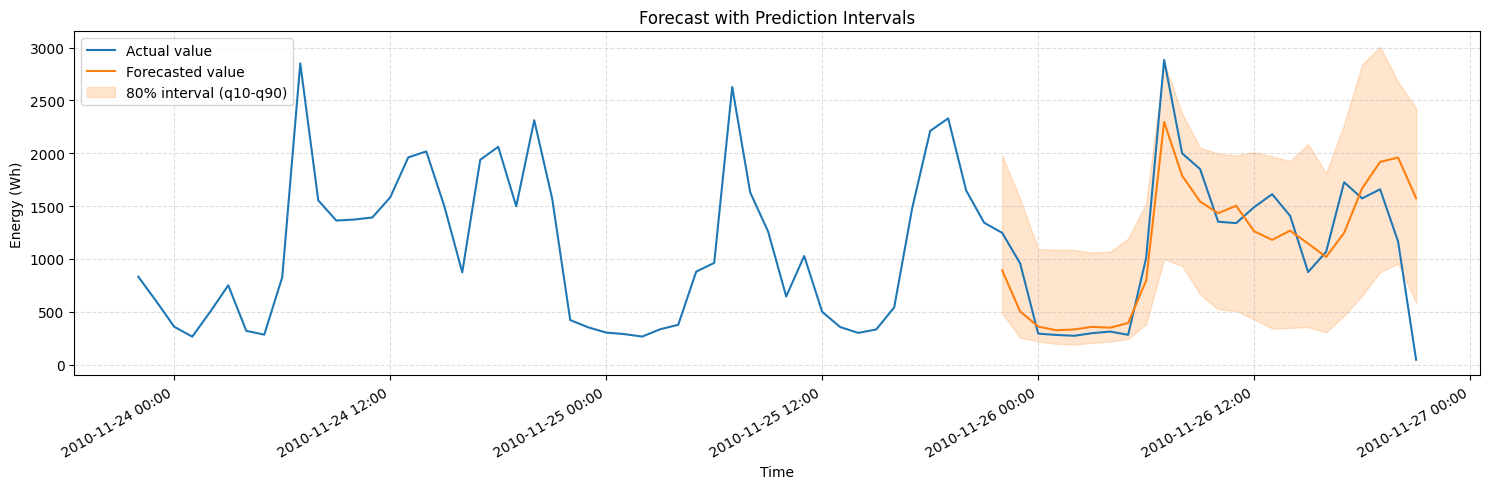

In [14]:
forecasted_timeseries = forecast.model_dump()["forecast_series"]["values"]

times = [d["time"] for d in forecasted_timeseries]
values = [d["value"] for d in forecasted_timeseries]
q10 = [d["quantiles"]["0.1"] for d in forecasted_timeseries]
q90 = [d["quantiles"]["0.9"] for d in forecasted_timeseries]

fig, ax = plt.subplots(figsize=(15, 5))

# Actual value
ax.plot(
    df.iloc[-24 * 3 :]["time"],
    df.iloc[-24 * 3 :]["value"],
    color="tab:blue",
    label="Actual value",
)

# Forecasted value
ax.plot(times, values, color="tab:orange", label="Forecasted value")

# 80 % prediction interval (q10 - q90)
ax.fill_between(times, q10, q90, alpha=0.20, color="tab:orange", label="80% interval (q10-q90)")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d %H:%M"))
fig.autofmt_xdate(rotation=30)

ax.set_title("Forecast with Prediction Intervals")
ax.set_xlabel("Time")
ax.set_ylabel("Energy (Wh)")
ax.legend()
ax.grid(linestyle="--", alpha=0.4)

plt.tight_layout()